# Exploratory data analysis: Northwind lineage benchmark

Milestone 2 of *Evaluating lineage link prediction with Valentine*.

The data comes from the RDDL paper's repository ([dudenzz/lineage](https://github.com/dudenzz/lineage)), cloned into `lineage/`
(see the README). We look at three splits:

| split | folder | content |
|---|---|---|
| `train` | `lineage/csv/train` | Northwind + objects of several lineage scenarios + `DataLineage.csv` |
| `test` | `lineage/csv/test` | Northwind + one scenario chain + `DataLineage.csv` |
| `multi` | `lineage/results_csv/multi_scenario` | several chains incl. temporary tables + `lineage.csv` |

The analysis has two parts:

1. **Basic analysis**: size, structure and quality of the data, and the shape of the lineage.
2. **Specific analysis**: how much of the evidence Valentine relies on (shared values for data matching,
   similar column names for schema matching) is actually present for true lineage links, compared with
   pairs of tables that are *not* linked.

All figures are written to `docs/figures/` for the report.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..", "src").resolve()))

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from eda import PAIR_LABELS, VALUE_MATCH, column_profile, evaluation_links, pair_scores, usable
from lineage_data import load_all

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 70)

FIGURES = Path("..", "docs", "figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Chart colours: blue marks lineage, neutral greys everything else;
# three-category charts use the first three validated categorical slots.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, LIGHT_GREY, MUTED, GRID, SURFACE = "#898781", "#c3c2b7", "#52514e", "#e1e0d9", "#ffffff"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 8,
    "axes.edgecolor": LIGHT_GREY, "axes.labelcolor": MUTED, "axes.titlesize": 8.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

splits = load_all()

## 1. Basic analysis

### 1.1 Objects in each split

In [2]:
def column_type(col):
    values = col.dropna()
    if values.empty:
        return "empty"
    if pd.to_numeric(values, errors="coerce").notna().all():
        return "numeric"
    if pd.to_datetime(values, errors="coerce", format="mixed").notna().all():
        return "date"
    return "text"


rows = []
for split in splits.values():
    for name in split.objects:
        df = split.tables.get(name)
        types = pd.Series([column_type(df[c]) for c in df.columns]).value_counts() if df is not None else pd.Series(dtype=int)
        rows.append({
            "split": split.name,
            "object": split.display[name],
            "kind": split.kind(name),
            "file": df is not None,
            "rows": len(df) if df is not None else None,
            "columns": df.shape[1] if df is not None else None,
            "numeric": types.get("numeric", 0),
            "date": types.get("date", 0),
            "text": types.get("text", 0),
            "missing_%": round(100 * df.isna().mean().mean(), 1) if df is not None and len(df) else None,
        })
overview = pd.DataFrame(rows)
overview

,split,object,kind,file,rows,columns,numeric,date,text,missing_%
0,train,Categories,original,True,8.0,4.0,1,0,3,0.0
1,train,CustomerCustomerDemo,original,True,0.0,2.0,0,0,0,NaN
2,train,CustomerDemographics,original,True,0.0,2.0,0,0,0,NaN
3,train,Customers,original,True,91.0,11.0,0,0,11,8.3
4,train,Employees,original,True,11.0,18.0,2,0,16,19.7
5,train,EmployeeTerritories,original,True,49.0,2.0,2,0,0,0.0
6,train,FinalAtRiskLog,unlogged,True,0.0,5.0,0,0,0,NaN
7,train,FinalManagerialSalesAudit,final,True,1.0,3.0,1,0,2,0.0
8,train,FinalSupervisionAudit,final,True,8.0,3.0,2,0,1,0.0
9,train,FinalSupplyChainAudit,unlogged,True,0.0,3.0,0,0,0,NaN


In [3]:
summary = overview.groupby("split").agg(
    objects=("object", "size"),
    original=("kind", lambda k: (k == "original").sum()),
    derived=("kind", lambda k: (~k.isin(["original", "unlogged"])).sum()),
    unlogged=("kind", lambda k: (k == "unlogged").sum()),
    without_file=("file", lambda f: (~f).sum()),
    empty=("rows", lambda r: (r == 0).sum()),
    numeric_cols=("numeric", "sum"),
    date_cols=("date", "sum"),
    text_cols=("text", "sum"),
).reindex(["train", "test", "multi"])
summary

,objects,original,derived,unlogged,without_file,empty,numeric_cols,date_cols,text_cols
split,,,,,,,,,
train,27,13,10,4,2,4,44,8,72
test,17,13,4,0,1,2,30,3,60
multi,16,4,12,0,0,0,31,12,37


`kind` is derived from the lineage log: an object is *derived* when it is the target of a lineage link
(view, derived table, temporary or final table, by its name prefix), *original* when it is one of the
13 Northwind tables, and *unlogged* when it is a derived object left over from another scenario whose
lineage is **not** in this split's log.

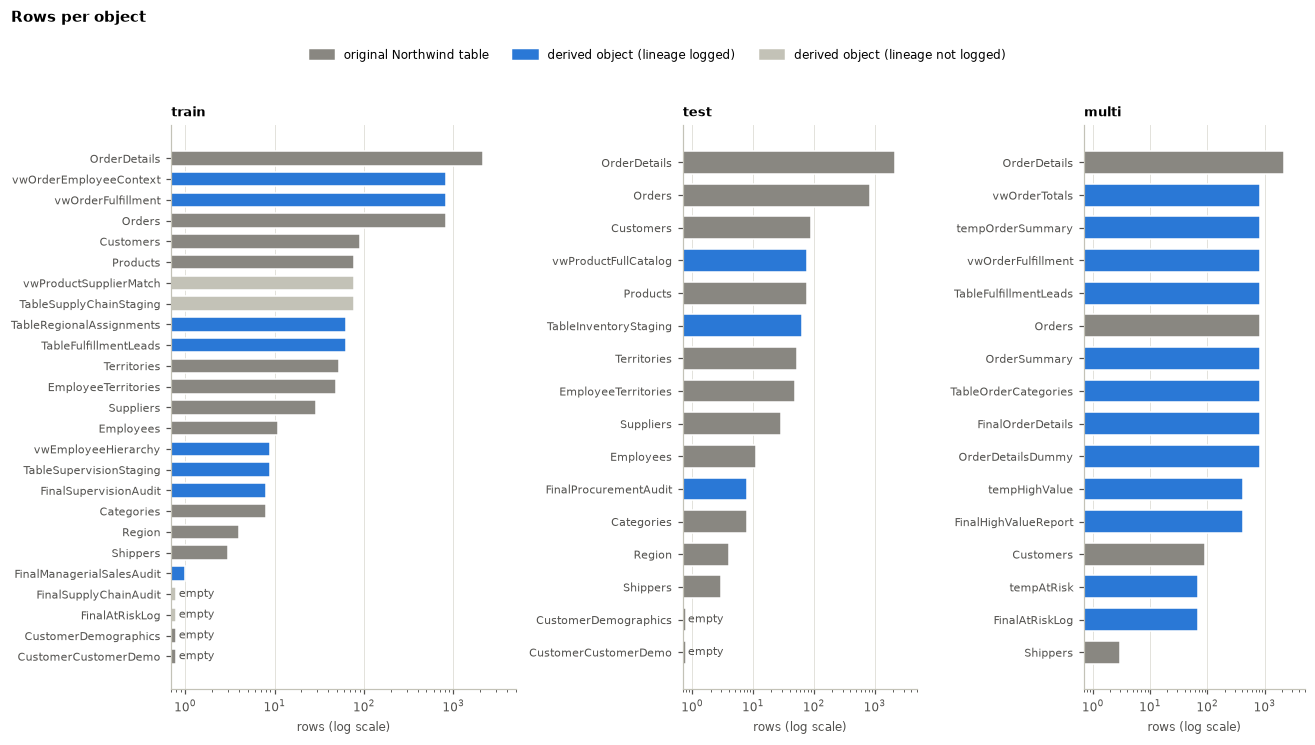

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6.2), gridspec_kw={"width_ratios": [25, 17, 16]})
for ax, (name, split) in zip(axes, splits.items()):
    part = overview[(overview.split == name) & overview.file].sort_values("rows")
    colors = [GREY if k == "original" else LIGHT_GREY if k == "unlogged" else BLUE for k in part.kind]
    ax.barh(part.object, part.rows.clip(lower=0.8), color=colors, height=0.7, edgecolor=SURFACE, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 5000)
    ax.grid(axis="y", visible=False)
    for y, (obj, rows_) in enumerate(zip(part.object, part.rows)):
        if rows_ == 0:
            ax.text(0.85, y, "empty", va="center", fontsize=7, color=MUTED)
    ax.set_title(f"{name}")
    ax.set_xlabel("rows (log scale)")
    ax.tick_params(axis="y", labelsize=7.5)
fig.legend(handles=[Patch(color=GREY, label="original Northwind table"),
                    Patch(color=BLUE, label="derived object (lineage logged)"),
                    Patch(color=LIGHT_GREY, label="derived object (lineage not logged)")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Rows per object", x=0.01, ha="left", y=1.08, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "eda_01_table_sizes.png")
plt.show()

### 1.2 Data quality

In [5]:
quality = []
for split in splits.values():
    lineage_objects = {o for link in split.links for o in link}
    replacement = sum(int(df[c].astype(str).str.contains("\ufffd").sum())
                      for df in split.tables.values() for c in df.columns)
    quality.append({
        "split": split.name,
        "lineage objects without a file": ", ".join(split.display[o] for o in sorted(lineage_objects) if o not in split.tables) or "-",
        "empty tables": ", ".join(split.display[o] for o in sorted(split.tables) if len(split.tables[o]) == 0) or "-",
        "unlogged derived objects": ", ".join(split.display[o] for o in split.objects if split.kind(o) == "unlogged") or "-",
        "byte-string values repaired": split.byte_strings,
        "values with broken characters": replacement,
    })
pd.DataFrame(quality).set_index("split").T

split,train,test,multi
lineage objects without a file,"##TempJoinBuffer, ##TempSupervisionBuffer",##TempProcurementBuffer,-
empty tables,"CustomerCustomerDemo, CustomerDemographics, FinalAtRiskLog, FinalS...","CustomerCustomerDemo, CustomerDemographics",-
unlogged derived objects,"FinalAtRiskLog, FinalSupplyChainAudit, TableSupplyChainStaging, vw...",-,-
byte-string values repaired,29,17,0
values with broken characters,0,0,0


In [6]:
# A column whose name contradicts its content (multi split)
leads = splits["multi"].tables["tablefulfillmentleads"]
orders = splits["multi"].tables["vworderfulfillment"]
print("TableFulfillmentLeads.CustomerID, first values:", leads["CustomerID"].head(3).tolist())
print("share of its values that are OrderIDs:",
      round(leads["CustomerID"].isin(orders["OrderID"]).mean(), 2))

TableFulfillmentLeads.CustomerID, first values: ['10843', '10844', '10845']
share of its values that are OrderIDs: 1.0


Notes on the file format, handled in `src/lineage_data.py`: files are `;` separated; `train`/`test` use `\r`
line endings, add a second row with Python type names and write nulls as `None`; `multi` uses `\n`
and `NULL`. Object names differ between files and logs (`vwOrderFulfillment.csv` vs `vw_OrderFulfillment`,
`OrderDetails.csv` vs `[Order Details]`, `tempAtRisk.csv` vs `##TempAtRisk`) and are normalised before matching.

### 1.3 Lineage structure

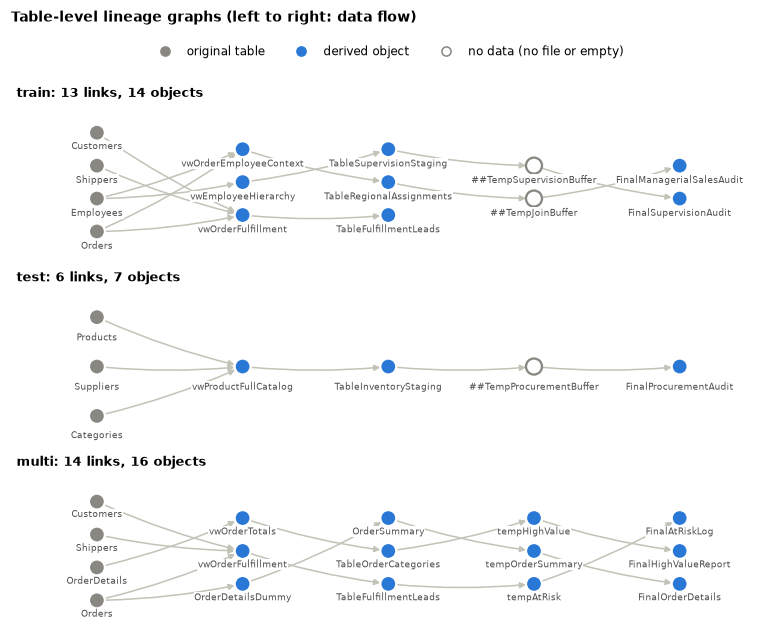

In [7]:
def draw_lineage(ax, split):
    graph = nx.DiGraph(sorted(split.links))  # sorted: same layout on every run
    for layer, nodes in enumerate(nx.topological_generations(graph)):
        for node in nodes:
            graph.nodes[node]["layer"] = layer
    pos = nx.multipartite_layout(graph, subset_key="layer", align="vertical")
    data = usable(split)
    fill = [SURFACE if n not in data else GREY if split.kind(n) == "original" else BLUE for n in graph]
    nx.draw_networkx_edges(graph, pos, ax=ax, edge_color=LIGHT_GREY, width=1, arrowsize=8,
                           node_size=110, connectionstyle="arc3,rad=0.05")
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=fill, node_size=110,
                           edgecolors=[GREY if n not in data else SURFACE for n in graph], linewidths=1.5)
    for node, (x, y) in pos.items():
        ax.text(x, y - 0.12, split.display[node], ha="center", va="top", fontsize=6, color=MUTED,
                bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 0.4})
    ax.set_title(f"{split.name}: {graph.number_of_edges()} links, {graph.number_of_nodes()} objects")
    ax.axis("off")
    ax.margins(x=0.08, y=0.2)


fig, axes = plt.subplots(3, 1, figsize=(7.0, 5.4))
for ax, split in zip(axes, splits.values()):
    draw_lineage(ax, split)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=GREY, markersize=6, label="original table"),
                    Line2D([], [], marker="o", ls="", color=BLUE, markersize=6, label="derived object"),
                    Line2D([], [], marker="o", ls="", markerfacecolor=SURFACE, markeredgecolor=GREY,
                           markersize=6, label="no data (no file or empty)")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Table-level lineage graphs (left to right: data flow)", x=0.01, ha="left", y=1.06, fontweight="bold", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "eda_02_lineage_graphs.png")
plt.show()

In [8]:
stats = []
for split in splits.values():
    graph = nx.DiGraph(split.links)
    links = evaluation_links(split)
    stats.append({
        "split": split.name,
        "lineage log rows": len(split.lineage_rows),
        "table-level links": len(split.links),
        "targets with >1 source (joins)": sum(1 for n in graph if graph.in_degree(n) > 1),
        "longest chain (links)": nx.dag_longest_path_length(graph),
        "evaluable links (direct)": sum(1 for k in links.values() if k == "direct"),
        "evaluable links (bridged over a missing table)": sum(1 for k in links.values() if k == "bridged"),
    })
stats = pd.DataFrame(stats).set_index("split")
stats

,lineage log rows,table-level links,targets with >1 source (joins),longest chain (links),evaluable links (direct),evaluable links (bridged over a missing table)
split,,,,,,
train,520,13,2,4,9,2
test,269,6,1,4,4,1
multi,9274,14,1,4,14,0


The lineage log is **row-level** (one entry per source row and target row), as in the RDDL paper.
Valentine compares tables and columns, so we evaluate at **table level**: a link `A -> B` exists when at
least one row of `B` was derived from `A`. Links into or out of objects without data cannot be observed;
`A -> ##Temp -> B` is *bridged* to `A -> B`.

## 2. Specific analysis: is Valentine's evidence there?

For every ordered pair of usable tables `(A, B)` we approximate the two signals Valentine uses
(`src/eda.py`):

* **value score**: for each column of `B`, the share of its distinct values that also occur in some
  column of `A` (containment); averaged over `B`'s columns. This is the signal of instance-based
  matchers (Jaccard, Distribution-based, COMA with instances).
* **name score**: for each column of `B`, the best string similarity to a column name of `A`; averaged.
  This is the signal of schema-based matchers (COMA, Cupid, Similarity Flooding).

Each pair is labelled with its ground-truth relation: `lineage` (A -> B), `reverse` (B -> A), `indirect`
(an ancestor further up the chain), `sibling` (derived from a common source), `unlogged` (involves a derived
object whose lineage is not logged) or `unrelated`.

In [9]:
pairs = pd.concat([pair_scores(s) for s in splits.values()], ignore_index=True)
pairs.groupby("label")[["value_mean", "value_max", "name_mean"]].agg(["count", "median", "mean"]).round(2).reindex(PAIR_LABELS)

value_mean              value_max              name_mean         \
               count median  mean     count median  mean     count median   
label                                                                       
lineage           30   0.67  0.60        30    1.0  1.00        30   0.78   
reverse           30   0.35  0.43        30    1.0  0.91        30   0.58   
indirect          84   0.31  0.33        84    1.0  0.81        84   0.55   
sibling            6   0.55  0.58         6    1.0  1.00         6   0.72   
unlogged          78   0.12  0.20        78    0.6  0.56        78   0.44   
unrelated        614   0.14  0.19       614    1.0  0.61       614   0.48   

                 
           mean  
label            
lineage    0.72  
reverse    0.65  
indirect   0.60  
sibling    0.66  
unlogged   0.46  
unrelated  0.51

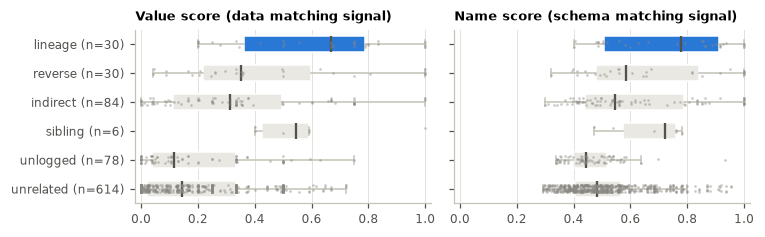

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2), sharey=False)
for ax, (column, title) in zip(axes, [("value_mean", "Value score (data matching signal)"),
                                       ("name_mean", "Name score (schema matching signal)")]):
    groups = [pairs.loc[pairs.label == label, column] for label in PAIR_LABELS]
    box = ax.boxplot(groups, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
                     medianprops={"color": MUTED, "linewidth": 1.5},
                     whiskerprops={"color": LIGHT_GREY}, capprops={"color": LIGHT_GREY})
    for patch, label in zip(box["boxes"], PAIR_LABELS):
        patch.set(facecolor=BLUE if label == "lineage" else "#e9e8e3", edgecolor=SURFACE)
    for i, values in enumerate(groups, start=1):
        jitter = (pd.Series(range(len(values))) % 7 - 3) * 0.04
        ax.scatter(values, i + jitter.values, s=3, color=GREY, alpha=0.45, linewidths=0, zorder=3)
    ax.set_yticks(range(1, len(PAIR_LABELS) + 1),
                  [f"{label} (n={len(g)})" for label, g in zip(PAIR_LABELS, groups)])
    ax.invert_yaxis()
    ax.set_xlim(-0.02, 1.02)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
axes[1].tick_params(axis="y", labelleft=False)
fig.tight_layout()
fig.savefig(FIGURES / "eda_03_scores_by_relation.png")
plt.show()

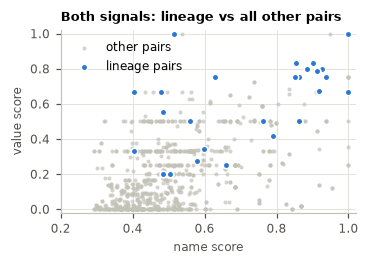

In [11]:
fig, ax = plt.subplots(figsize=(3.4, 2.45))
other = pairs[pairs.label != "lineage"]
lineage = pairs[pairs.label == "lineage"]
ax.scatter(other.name_mean, other.value_mean, s=7, color=LIGHT_GREY, alpha=0.7, linewidths=0, label="other pairs")
ax.scatter(lineage.name_mean, lineage.value_mean, s=18, color=BLUE, edgecolors=SURFACE, linewidths=1,
           label="lineage pairs", zorder=3)
ax.set_xlabel("name score")
ax.set_ylabel("value score")
ax.set_xlim(0.2, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="upper left")
ax.set_title("Both signals: lineage vs all other pairs")
fig.tight_layout()
fig.savefig(FIGURES / "eda_04_name_vs_value.png")
plt.show()

### 2.1 What happens to the columns of a derived table?

For each evaluable lineage link we classify every target column by its best value match in the source:
**same name, same values** (easy for both kinds of matchers), **renamed, same values** (only data matching
can find it) and **values changed** (new, computed or transformed columns: neither signal helps).

In [12]:
profiles = []
for split in splits.values():
    data = usable(split)
    for (source, target), kind in evaluation_links(split).items():
        profile = column_profile(data[source], data[target])
        profile["link"] = f"{split.name}: {split.display[source]} -> {split.display[target]}"
        profile["bridged"] = kind == "bridged"
        profiles.append(profile)
profiles = pd.concat(profiles, ignore_index=True)
CATEGORIES = ["same name, same values", "renamed, same values", "values changed"]
profiles.category.value_counts().reindex(CATEGORIES)

category
same name, same values    47
renamed, same values      25
values changed            50
Name: count, dtype: int64

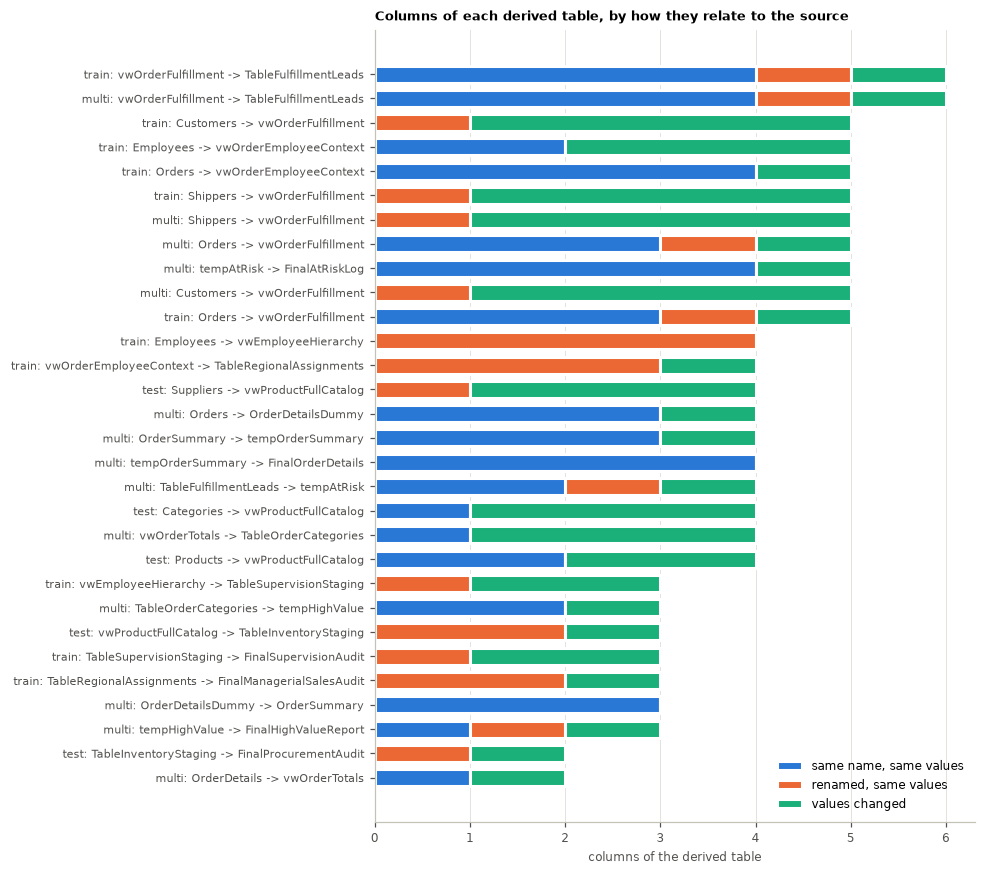

In [13]:
counts = profiles.groupby(["link", "category"]).size().unstack(fill_value=0).reindex(columns=CATEGORIES, fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9, 8))
left = pd.Series(0, index=counts.index)
for category, color in zip(CATEGORIES, [BLUE, ORANGE, AQUA]):
    ax.barh(counts.index, counts[category], left=left, color=color, height=0.7,
            edgecolor=SURFACE, linewidth=2, label=category)
    left += counts[category]
ax.set_xlabel("columns of the derived table")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7.5)
ax.legend(loc="lower right")
ax.set_title("Columns of each derived table, by how they relate to the source")
fig.tight_layout()
fig.savefig(FIGURES / "eda_05_column_categories.png")
plt.show()

In [14]:
profiles[profiles.category == "renamed, same values"][["link", "target_column", "best_source_column", "containment"]].round(2)

,link,target_column,best_source_column,containment
1,train: vwOrderEmployeeContext -> TableRegionalAssignments,SourceOrderID,OrderID,1.00
2,train: vwOrderEmployeeContext -> TableRegionalAssignments,EmpName,LastName,1.00
3,train: vwOrderEmployeeContext -> TableRegionalAssignments,Country,ShipCountry,1.00
8,train: vwOrderFulfillment -> TableFulfillmentLeads,RequiredDate,OrderDate,1.00
11,train: Orders -> vwOrderFulfillment,CustomerName,ShipName,0.94
20,train: Employees -> vwEmployeeHierarchy,SubordinateID,EmployeeID,1.00
21,train: Employees -> vwEmployeeHierarchy,SubordinateName,LastName,1.00
22,train: Employees -> vwEmployeeHierarchy,ManagerID,EmployeeID,1.00
23,train: Employees -> vwEmployeeHierarchy,ManagerName,LastName,1.00
30,train: vwEmployeeHierarchy -> TableSupervisionStaging,EmpID,SubordinateID,1.00


Most of these are real renames (`CompanyName -> CustomerName`, `EmployeeID -> SubordinateID`). A few are
coincidences of the value-based check, which is exactly the kind of error an instance-based matcher can make:
`RequiredDate` matches `OrderDate` because the two date ranges overlap, `CustomerName` matches `ShipName`
because Northwind ships to the customer's name, and `OrderID -> CustomerID` in `multi` comes from the
mislabelled column found in section 1.2.

### 2.2 Direction: is the source more similar to the target than the other way round?

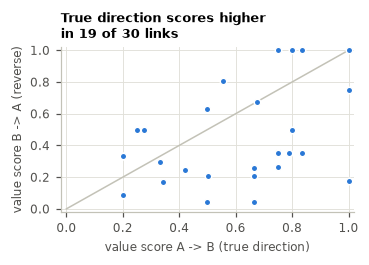

In [15]:
lookup = pairs.set_index(["split", "source", "target"]).value_mean
direction = lineage.assign(reverse_score=[lookup[(r.split, r.target, r.source)] for r in lineage.itertuples()])
fig, ax = plt.subplots(figsize=(3.4, 2.45))
ax.plot([0, 1], [0, 1], color=LIGHT_GREY, linewidth=1)
ax.scatter(direction.value_mean, direction.reverse_score, s=18, color=BLUE, edgecolors=SURFACE, linewidths=1, zorder=3)
ax.set_xlabel("value score A -> B (true direction)")
ax.set_ylabel("value score B -> A (reverse)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
correct = int((direction.value_mean > direction.reverse_score).sum())
ax.set_title(f"True direction scores higher\nin {correct} of {len(direction)} links")
fig.tight_layout()
fig.savefig(FIGURES / "eda_06_direction.png")
plt.show()

### 2.3 Likely false positives: unlinked pairs with high value scores

In [16]:
pairs[pairs.label.isin(["unrelated", "unlogged"])].sort_values("value_mean", ascending=False).head(10).round(2)

,split,source,target,value_mean,value_max,name_mean,label
179,train,Products,vwProductSupplierMatch,0.75,1.0,0.93,unlogged
323,train,Territories,EmployeeTerritories,0.72,1.0,0.74,unrelated
579,test,Territories,EmployeeTerritories,0.72,1.0,0.74,unrelated
744,multi,TableFulfillmentLeads,OrderSummary,0.67,1.0,0.92,unrelated
819,multi,vwOrderFulfillment,OrderSummary,0.67,1.0,0.91,unrelated
495,test,OrderDetails,TableInventoryStaging,0.67,1.0,0.49,unrelated
491,test,OrderDetails,Products,0.65,1.0,0.67,unrelated
127,train,OrderDetails,Products,0.65,1.0,0.67,unrelated
75,train,EmployeeTerritories,Territories,0.64,1.0,0.72,unrelated
470,test,EmployeeTerritories,Territories,0.64,1.0,0.72,unrelated


In [17]:
# Small integer keys (e.g. EmployeeID 1-9, CategoryID 1-8) are contained in many unrelated columns,
# so the best single column almost always matches perfectly.
print("pairs whose best single column is fully contained, by relation:")
print((pairs.assign(perfect=pairs.value_max == 1).groupby("label").perfect.mean() * 100).round(0).reindex(PAIR_LABELS).astype(int).astype(str) + " %")

pairs whose best single column is fully contained, by relation:
label
lineage      100 %
reverse       77 %
indirect      68 %
sibling      100 %
unlogged      49 %
unrelated     50 %
Name: perfect, dtype: str


## 3. Main outcomes

In [18]:
lin, unrel = pairs[pairs.label == "lineage"], pairs[pairs.label == "unrelated"]
evaluable = sum(len(evaluation_links(s)) for s in splits.values())
cat = profiles.category.value_counts(normalize=True).mul(100).round(0)
outcomes = {
    "objects (train/test/multi)": "/".join(str(n) for n in summary.objects),
    "table-level links (train/test/multi)": "/".join(str(n) for n in stats["table-level links"]),
    "evaluable links in total": evaluable,
    "median value score, lineage vs unrelated": f"{lin.value_mean.median():.2f} vs {unrel.value_mean.median():.2f}",
    "median name score, lineage vs unrelated": f"{lin.name_mean.median():.2f} vs {unrel.name_mean.median():.2f}",
    "target columns: same name / renamed / values changed (%)": "/".join(str(int(cat.get(c, 0))) for c in CATEGORIES),
    "true direction scores higher": f"{correct} of {len(direction)}",
    "unrelated pairs with a perfectly contained column (%)": int(round(100 * (unrel.value_max == 1).mean())),
}
pd.Series(outcomes, name="value").to_frame()

,value
objects (train/test/multi),27/17/16
table-level links (train/test/multi),13/6/14
evaluable links in total,30
"median value score, lineage vs unrelated",0.67 vs 0.14
"median name score, lineage vs unrelated",0.78 vs 0.48
target columns: same name / renamed / values changed (%),39/20/41
true direction scores higher,19 of 30
unrelated pairs with a perfectly contained column (%),50
